<img src=https://courseware.decoded.com/images/decoded/logo-decoded.png align=left width=100px/>

# From EDA To Preprocessing
---
<small>© COPYRIGHT 2026 DECODED LIMITED. ALL RIGHTS RESERVED. Web: https://decoded.com/ </small>

## Introduction

This workbook bridges exploratory data analysis and machine learning by introducing somes of the intial steps taken to preprocess data so that it be used for modelling.

In the previous section, we explored a university performance dataset. In this notebook, we use the same scenario to prepare data for modelling.

By the end, you will be able to:

- explain why we split data into training and test sets
- separate features (`X`) from the target (`y`)
- spot and remove data leakage
- encode categorical columns
- scale numerical columns
- run simple checks to confirm preprocessing worked

We are not trying to build the most advanced model. The aim is to understand the preprocessing decisions clearly.

### What You Will Learn

* **Data Splitting:** How and why we divide our dataset into feature target then train/test set for an ML prediction task.
* **Feature Inspection:** How to detect constant features, derivative relationships, and multicollinearity using correlation analysis
* **Categorical Encoding:** When to use ordinal encoding (ranked categories) versus one-hot encoding
* **Standardise features** to ensure fair model performance across all scales

### Stretch Materials

* **Use transformations** (binning) to normalise skewed distributions and reduce outlier influence


## 1. Import the libraries and load the data

We start with the same two data files from the first workshop.

`pandas` helps us work with tables.  
`train_test_split` helps us split the data for modelling.  
`StandardScaler` helps us put numerical columns onto a similar scale.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

In [ ]:
# Load the datasets



# Display the shapes of the datasets


In [ ]:
# display the first few rows of the university dataset


### Checkpoint

Before we preprocess, check that the dataset looks familiar from the previous workshop. We still have university-level information, including applications, enrolments, satisfaction, region and outcome.

In [ ]:
# check the dataset before starting to preprocess the data



## 2. Clean column names

Some column names contain spaces. This is common in real data exported from spreadsheets or systems.

We clean column names early because it makes the rest of the code easier to read and reduces small errors.

In [ ]:
# .str.strip() removes spaces at the start and end of each column name.
# .str.replace(" ", "_") replaces spaces inside names with underscores.


## 3. Join the lookup table

In the previous workshop, we used a join to add useful context. We keep that idea here.

The main dataset has a `Region` column. The lookup table also has a `Region` column. That shared column lets us add advisor and support budget information to each university.

In [ ]:
# A left join keeps every row in the main university dataset.
# It adds matching support information where the Region is the same.


In [ ]:
# Quick check: after the join, we should still have the same number of rows.


## 4. Define the modelling question

Our target is `Strong_Outcome`.

In this dataset:

- `Strong_Outcome = 1` means the university has a strong outcome.
- `Strong_Outcome = 0` means it does not.

The modelling question is:

> Based on information about a university, can we predict whether it is likely to have a strong outcome?

In [ ]:
# The target is the column we want to predict.


## 5. Remove leakage and identifier columns

Data leakage happens when we accidentally give the model information it would not really have at prediction time.

Here, `Graduation_Rate` is risky because `Strong_Outcome` was created from it. If we leave it in, the model has an unfair shortcut.

We also remove `University_ID`. It is a label, not a meaningful pattern.

In [ ]:
columns_to_remove = [
    "University_ID",      # identifier, not a useful pattern
    "Graduation_Rate"     # leakage risk because it directly defines the target
]

## remove those unwanted columns from the dataframe and create a new dataframe for modeling



## 6. Split features and target

In machine learning pipelines, you will often see:

- `X` for the features used to make a prediction
- `y` for the target we want to predict

The names are short, but the idea is simple: `X` is the input and `y` is the answer.

In [ ]:
# split the data into features and target



# display the shapes of the features and target datasets
print("Feature table shape:", X.shape)
print("Target shape:", y.shape)

## 7. Create the train-test split

We split the data before we calculate preprocessing values such as averages and standard deviations.

Why? Because the test set should act like new, unseen data.

We use:

- **training data** to learn patterns and preprocessing values
- **test data** to check whether the final process works on unseen rows



### The Split

We split our data **immediately**. We want to keep 20% of our data*



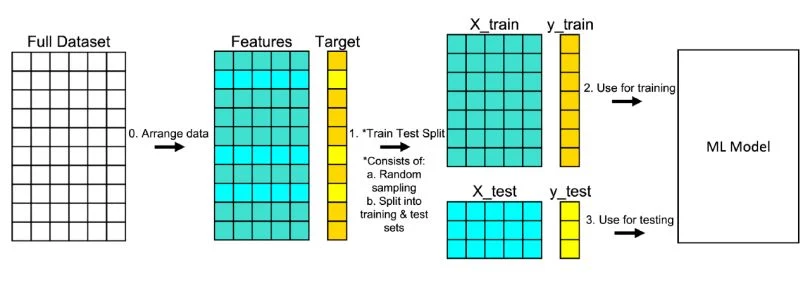

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # 20% of rows go into the test set
    random_state=42,      # makes the split reproducible
    stratify=y            # keeps the target balance similar in both sets
)



In [ ]:
## Create a simple report showing the number of rows and columns in each of the training and test sets.


#### What's with the random state?

if we call train test split without a random state it will retrieve a new set of rows for the X_train,X_test,y_train,y_test this is problematic because it is hard to tell where our model improvements to predictions can be attribute to our modelling effort of that we luckily got a 'good' slice of data

#### Why Stratify?

`train_test_split` by default will randomly select rows from the dataframe - as a consequences there is a chance the target labels may be disproportionately present in either the training or test set not capturing the appropriate partition.

In [ ]:
# Check that the target balance is similar in the training and test sets.

# Check that the target balance is similar in the training and test sets.


## 8. Separate numerical and categorical columns

Most models need numbers. Our dataset has a mix of:

- numerical columns, such as `Applications` and `Spend_Per_Student`
- categorical columns, such as `Region` and `Funding_Band`

We handle these groups differently.

In [ ]:
# select the numeric and categorical columns from the training set

# display the numeric and categorical columns


## 9. Encode categorical columns

Categorical values are words or labels. For example, `Region` might contain `North`, `South` or `East`.

A model cannot usually use those words directly, so we convert them into numeric columns using one-hot encoding.

Important rule: learn the categories from the training data, then apply the same structure to the test data.

In [ ]:
# pd.get_dummies() creates one numeric column per category.





In [ ]:
# Apply it to the test data


## 10. Align train and test columns

Sometimes a category appears in one split but not the other.

For example, the training set might contain `Funding_Band_High`, but the test set might not. We align the columns so both datasets have the same structure.

In [ ]:
# align the columns of the training and test sets so they have the same columns in the same order.



## 11. Scale numerical columns

Some numerical columns have very different ranges.

Some models are sensitive to feature scale. A feature with large values can dominate a feature with small values, even when both are useful.

For example:

- `Applications` may be in the thousands
- `Student_Satisfaction` may be between 0 and 100

Scaling helps many models treat numerical features more evenly.

Perfect CASE:
- all the features are on the same range
- all the features are symmetrical

Imperfect Case 1:
- feature has different range
- but it is symmmetrical

Imperfect Case 2:
- features have differing ranges
- some features are asymmetrical and exhibit long tail 

Important rule: fit the scaler on the training data only. Then use it to transform both training and test data.

### Which case are we facing in this scenario?

#### How do we fix it : we apply scaling

In [ ]:
scaler = StandardScaler()

# Fit means: learn the mean and standard deviation from the training data.



In [ ]:

# Transform means: apply that same scaling to both train and test.


## 12. Run final checks

Good preprocessing should leave us with:

- matching train and test columns
- no missing values
- all feature columns numeric
- the target kept separate from the features

In [ ]:
checks = {
    "train_test_columns_match": list(X_train_encoded.columns) == list(X_test_encoded.columns),
    "no_missing_train_values": X_train_encoded.isna().sum().sum() == 0,
    "no_missing_test_values": X_test_encoded.isna().sum().sum() == 0,
    "all_train_features_numeric": all(pd.api.types.is_numeric_dtype(X_train_encoded[col]) for col in X_train_encoded.columns),
    "target_not_in_features": target_column not in X_train_encoded.columns
}

checks

In [ ]:
assert all(checks.values())
print("All preprocessing checks passed.")

## 13. Reflection

Use these questions to connect the code back to the workflow:

1. Why did we remove `Graduation_Rate` before modelling?
2. Why did we split the data before scaling?
3. Why do the training and test columns need to match after encoding?
4. Which preprocessing step felt most important for making the data model-ready?

## Optional approach in feature engineering: bucketing and binning

There are other preprocessing approaches for numerical data, including bucketing and binning. We are keeping that idea here as an **optional preprocessing approach**.

Bucketing means turning a continuous number into a smaller set of groups. For example, instead of using the exact `Student_Satisfaction` score, we could create groups such as `Developing`, `Secure` and `Strong`.

This can be useful when:

- you want to explain patterns in plain English
- exact values are noisy or less meaningful than ranges
- a model benefits from grouped values

It is not always better than keeping the original number. We will create a copy of the data so the main preprocessing route stays unchanged.


In [ ]:
# OPTIONAL DEMO ONLY
# We create copies so we do not change the main X_train and X_test tables.
X_train_binning_demo = X_train.copy()
X_test_binning_demo = X_test.copy()

print("Original training shape:", X_train.shape)
print("Binning demo shape:", X_train_binning_demo.shape)


### Option A: manual bucketing with `pd.cut()`

`pd.cut()` lets us choose the edges of the groups ourselves.

Here we group `Student_Satisfaction` into three bands:

- `Developing`: lower satisfaction
- `Secure`: middle satisfaction
- `Strong`: higher satisfaction

The important syntax is:

- `bins=` gives the numeric break points
- `labels=` gives the names for each group
- `include_lowest=True` includes the lowest value in the first bucket


In [ ]:
satisfaction_bins = [0, 70, 85, 100]
satisfaction_labels = ["Developing", "Secure", "Strong"]

X_train_binning_demo["Satisfaction_Bucket"] = pd.cut(
    X_train_binning_demo["Student_Satisfaction"],
    bins=satisfaction_bins,
    labels=satisfaction_labels,
    include_lowest=True
)

X_test_binning_demo["Satisfaction_Bucket"] = pd.cut(
    X_test_binning_demo["Student_Satisfaction"],
    bins=satisfaction_bins,
    labels=satisfaction_labels,
    include_lowest=True
)

X_train_binning_demo[["Student_Satisfaction", "Satisfaction_Bucket"]].head()


In [ ]:
# Check how many training rows sit in each bucket.
X_train_binning_demo["Satisfaction_Bucket"].value_counts().sort_index()


### Option B: automatic binning with `KBinsDiscretizer`

`KBinsDiscretizer` lets scikit-learn create bins for us.

In this example, we use `strategy="quantile"`. This tries to put a similar number of rows into each bin.

The key modelling rule still applies:

> Fit on the training data, then transform the training and test data.

This avoids using information from the test set when deciding the bin edges.


In [ ]:
from sklearn.preprocessing import KBinsDiscretizer

spend_binner = KBinsDiscretizer(
    n_bins=3,
    encode="ordinal",
    strategy="quantile"
)

X_train_binning_demo["Spend_Per_Student_Bin"] = spend_binner.fit_transform(
    X_train_binning_demo[["Spend_Per_Student"]]
).astype(int)

X_test_binning_demo["Spend_Per_Student_Bin"] = spend_binner.transform(
    X_test_binning_demo[["Spend_Per_Student"]]
).astype(int)

X_train_binning_demo[["Spend_Per_Student", "Spend_Per_Student_Bin"]].head()


In [ ]:
# The bin edges show where each group starts and ends.
# This helps us explain what the automatic bins mean.
spend_binner.bin_edges_[0]


### Should we use the binned version?

We will focus on the original approach, by scaling the numeric columns as in our main preprocessing route.

In a real project, you might compare two versions:

1. a model using the original numeric columns
2. a model using selected binned columns

The better choice depends on the problem, the model and how interpretable the features need to be.


## A final recap

A useful preprocessing workflow is not a long list of techniques. It is a set of defensible decisions.

In this notebook, we:

* split the data before preprocessing
* used stratification to preserve the target balance
* removed constant and directly derived features
* encoded categories based on their meaning
* compared binning with a continuous transformation
* scaled numerical features using training data only
* ran checks to confirm the final data was model-ready
